# ASTER band ratios over Cuprite, Nevada

ASTER is the sensor the original band-ratio table was written for. Its six narrow SWIR bands and five thermal bands separate minerals that Landsat and Sentinel-2 cannot, so the **25 ASTER ratios run on ASTER only**. This notebook runs all of them, plus the multi-sensor ratios ASTER can support, over Cuprite, Nevada, a classic hydrothermal-alteration test site (alunite, kaolinite and silica).

ASTER L1T is not on a STAC API at AWS (the `aster-l1t` bucket is public but has no catalogue), so this notebook uses the [Microsoft Planetary Computer](https://planetarycomputer.microsoft.com/dataset/aster-l1t) STAC API, which serves the same cloud-optimised GeoTIFFs and needs no account.

1. Search the catalogue
2. Identify the bands
3. Load and align the bands
4. Convert to radiance
5. Run one ratio
6. Run every ratio and composite

> **Only scenes up to 2008 have SWIR.** The SWIR detectors failed on 1 April 2008, and the Planetary Computer archive ends in 2006, so every scene here has all 14 bands.

In [ ]:
%pip install -q -e .. pystac-client planetary-computer rioxarray matplotlib pandas

In [1]:
import rockbands as rb
import pandas as pd
import planetary_computer
import rioxarray
import xarray as xr
from pystac_client import Client
from rasterio.enums import Resampling

## 1. Search the catalogue

Scenes recorded at night have thermal data only, so we keep the ones that also have VNIR and SWIR assets, and take the one with the least cloud.

In [2]:
bbox = [-117.32, 37.48, -117.10, 37.62]

catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)
search = catalog.search(collections=["aster-l1t"], bbox=bbox, datetime="2003-01-01/2006-12-31")
scenes = [i for i in search.items() if {"VNIR", "SWIR", "TIR"} <= set(i.assets)]
item = min(scenes, key=lambda i: i.properties.get("eo:cloud_cover", 0))

item.id, item.properties["datetime"], sorted(item.assets)[:3]

('AST_L1T_00308152006183834_20150515181406',
 '2006-08-15T18:38:34.177000Z',
 ['SWIR', 'TIR', 'VNIR'])

## 2. Identify the bands

ASTER files come in three groups: VNIR (bands 1, 2, 3N at 15 m), SWIR (bands 4 to 9 at 30 m) and TIR (bands 10 to 14 at 90 m). ASTER ratios are written in these band numbers. The table shows how much of each ASTER band is covered by bands of Sentinel-2 and Landsat 8: bands 5 to 7 all fall inside the single SWIR 2 band of the other sensors, which is why ratios built from them cannot be reproduced there.

In [3]:
rb.aster_band_coverage(["s2", "l8"])

**ASTER band coverage by other sensors (share of the ASTER band's range covered). '-' means none.**

| ASTER | Name | Range (nm) | s2 | l8 |
| --- | --- | --- | --- | --- |
| B1 | VNIR green | 520-600 | B2 (7%), B3 (44%) | B3 (75%), B8 (100%) |
| B2 | VNIR red | 630-690 | B4 (50%) | B4 (50%), B8 (83%) |
| B3 | VNIR NIR (3N) | 760-860 | B7 (19%), B8 (80%), B8A (6%) | B5 (10%) |
| B4 | SWIR 1 | 1600-1700 | B11 (59%) | B6 (50%) |
| B5 | SWIR 2 | 2145-2185 | B12 (100%) | B7 (100%) |
| B6 | SWIR 3 | 2185-2225 | B12 (100%) | B7 (100%) |
| B7 | SWIR 4 | 2235-2285 | B12 (100%) | B7 (100%) |
| B8 | SWIR 5 | 2295-2365 | - | - |
| B9 | SWIR 6 | 2360-2430 | - | - |
| B10 | TIR 1 | 8125-8475 | - | - |
| B11 | TIR 2 | 8475-8825 | - | - |
| B12 | TIR 3 | 8925-9275 | - | - |
| B13 | TIR 4 | 10250-10950 | - | B10 (50%) |
| B14 | TIR 5 | 10950-11650 | - | B10 (34%), B11 (21%) |

## 3. Load and align the bands

The three groups have different pixel sizes. We read each one, clip it to `bbox`, and bring VNIR (averaged down) and TIR (interpolated up) onto the 30 m SWIR grid so that every band lines up. Each layer is then named with its ASTER band id (`B3N` is accepted for band 3).

In [4]:
def read(asset, reference=None, resampling=Resampling.average):
    grid = rioxarray.open_rasterio(item.assets[asset].href).rio.clip_box(*bbox, crs="EPSG:4326")
    return grid if reference is None else grid.rio.reproject_match(reference, resampling=resampling)


swir = read("SWIR")
groups = {
    "VNIR": (["B1", "B2", "B3N"], read("VNIR", swir)),
    "SWIR": ([f"B{n}" for n in range(4, 10)], swir),
    "TIR": ([f"B{n}" for n in range(10, 15)], read("TIR", swir, Resampling.bilinear)),
}
dn = {band: layer.drop_vars("band") for ids, grid in groups.values() for band, layer in zip(ids, grid)}

pd.Series({band: layer.dtype.name for band, layer in dn.items()}, name="dtype").to_frame().T

,B1,B2,B3N,B4,B5,B6,B7,B8,B9,B10,B11,B12,B13,B14
dtype,uint8,uint8,uint8,uint8,uint8,uint8,uint8,uint8,uint8,uint16,uint16,uint16,uint16,uint16


## 4. Convert to radiance

ASTER L1T stores digital numbers. Each band has its own gain, so raw numbers cannot be compared across bands. `aster_dn_to_radiance` applies `(DN − 1) × coefficient` from the ASTER L1T product guide and turns the fill value 0 into NaN. VNIR and SWIR bands record a gain setting for every scene (`HGH`, `NOR`, `LO1` or `LO2`) in the product metadata. **This notebook assumes normal gain (`NOR`) for every band.** If your scene's metadata says otherwise, edit `gains`: a wrong gain rescales that band and every ratio that uses it. The thermal bands have a single gain.

In [5]:
gains = dict.fromkeys(dn, "NOR")
radiance = {band: rb.aster_dn_to_radiance(layer, band, gains[band]) for band, layer in dn.items()}

## 5. Run one ratio

ASTER ratios are named `aster_*` and use ASTER band numbers directly. `aster_kaolinite_index` is `(B4/B5) * (B8/B6)` (Ninomiya's KLI).

(B4/B5)*(B8/B6)


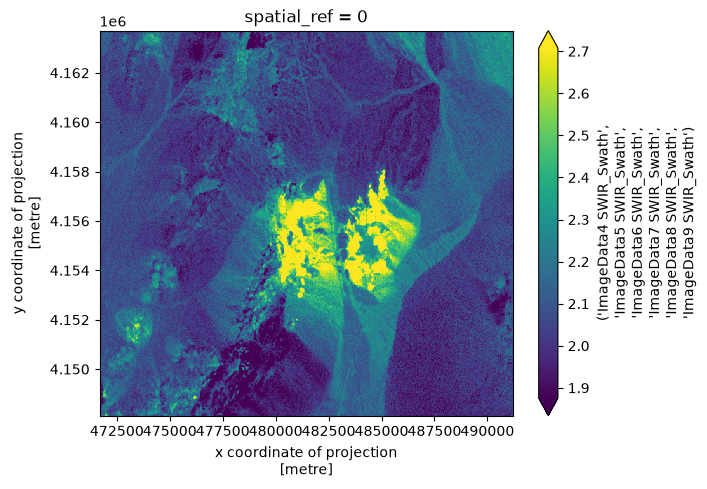

In [6]:
print(rb.get_ratio("aster_kaolinite_index").formula)

kli = rb.aster_kaolinite_index(radiance, sensor="aster")
kli.plot.imshow(robust=True, cmap="viridis", size=5);

## 6. Run every ratio and composite

`compute_all` returns the 25 ASTER ratios and the multi-sensor ratios whose bands ASTER has (green, red, NIR and SWIR 1). Radiance is used here instead of reflectance, which is enough for the relative comparisons these ratios are meant for.

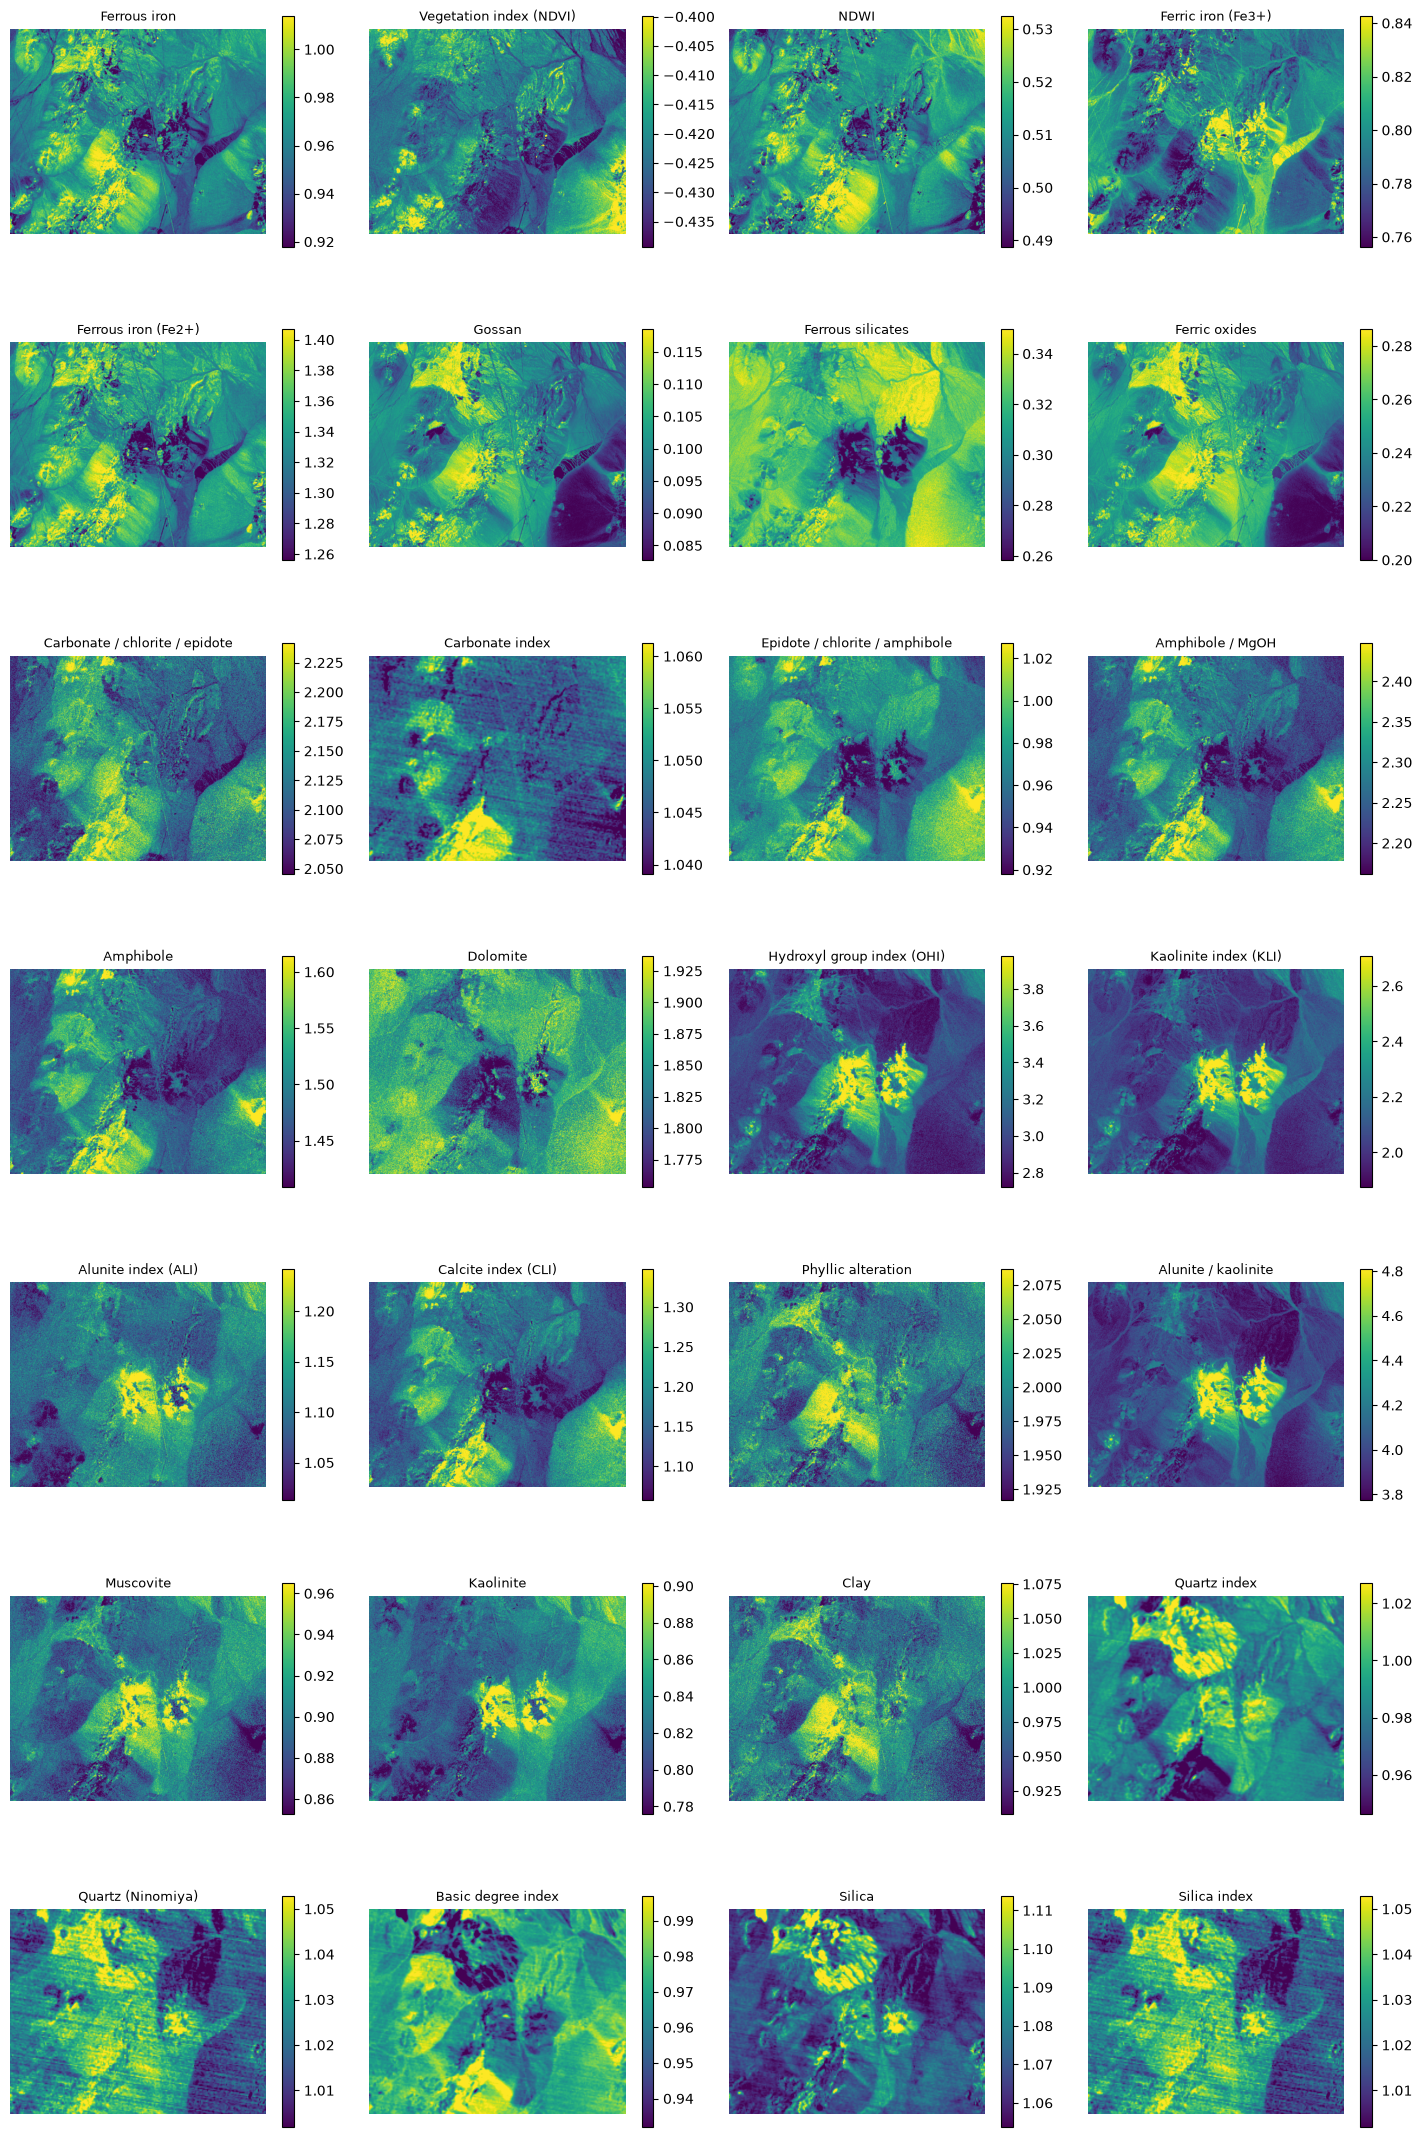

In [7]:
ratios = rb.compute_all(radiance, "aster", kind="ratio")
rb.plot_ratios(ratios, ncols=4);

ASTER has no blue band, so only the colour-infrared composite from the catalogue applies. You can also stack any three results into your own composite: here Ninomiya's hydroxyl (OHI), kaolinite (KLI) and alunite (ALI) indices are shown together as red, green and blue.

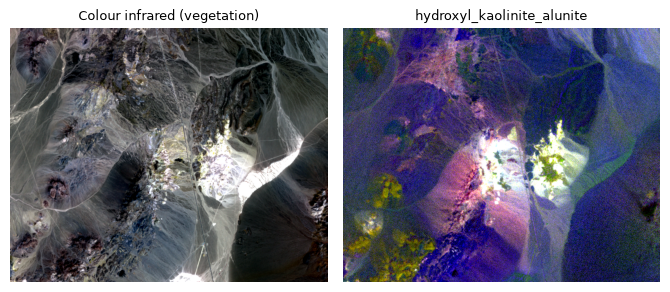

In [8]:
composites = rb.compute_all(radiance, "aster", kind="composite")
composites["hydroxyl_kaolinite_alunite"] = xr.concat(
    [ratios["aster_hydroxyl_index"], ratios["aster_kaolinite_index"], ratios["aster_alunite_index"]], dim="channel"
)
rb.plot_composites(composites, ncols=2);